# Project Title: Video Game Sales Analysis

In [1]:
import pandas as pd 
import numpy as np
import seaborn as sb
import matplotlib.pyplot as plt

In [2]:
df=pd.read_csv("../Datasets/vgsales.csv")
df

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37
...,...,...,...,...,...,...,...,...,...,...,...
16593,16596,Woody Woodpecker in Crazy Castle 5,GBA,2002.0,Platform,Kemco,0.01,0.00,0.00,0.00,0.01
16594,16597,Men in Black II: Alien Escape,GC,2003.0,Shooter,Infogrames,0.01,0.00,0.00,0.00,0.01
16595,16598,SCORE International Baja 1000: The Official Game,PS2,2008.0,Racing,Activision,0.00,0.00,0.00,0.00,0.01
16596,16599,Know How 2,DS,2010.0,Puzzle,7G//AMES,0.00,0.01,0.00,0.00,0.01


# Data Preparation:

In [3]:
(df.isnull().sum())

Rank              0
Name              0
Platform          0
Year            271
Genre             0
Publisher        58
NA_Sales          0
EU_Sales          0
JP_Sales          0
Other_Sales       0
Global_Sales      0
dtype: int64

In [4]:
df.dtypes

Rank              int64
Name             object
Platform         object
Year            float64
Genre            object
Publisher        object
NA_Sales        float64
EU_Sales        float64
JP_Sales        float64
Other_Sales     float64
Global_Sales    float64
dtype: object

In [5]:
df["Publisher"] = df["Publisher"].fillna("Unknown")

In [6]:
df.dropna(subset=["Year"], inplace=True)

In [7]:
(df.isnull().sum())

Rank            0
Name            0
Platform        0
Year            0
Genre           0
Publisher       0
NA_Sales        0
EU_Sales        0
JP_Sales        0
Other_Sales     0
Global_Sales    0
dtype: int64

In [8]:
df["Year"] = pd.to_datetime(df["Year"].astype(int).astype(str),format="%Y")
df["Year"]


0       2006-01-01
1       1985-01-01
2       2008-01-01
3       2009-01-01
4       1996-01-01
           ...    
16593   2002-01-01
16594   2003-01-01
16595   2008-01-01
16596   2010-01-01
16597   2003-01-01
Name: Year, Length: 16327, dtype: datetime64[ns]

In [9]:
df.dtypes

Rank                     int64
Name                    object
Platform                object
Year            datetime64[ns]
Genre                   object
Publisher               object
NA_Sales               float64
EU_Sales               float64
JP_Sales               float64
Other_Sales            float64
Global_Sales           float64
dtype: object

In [10]:
df["Genre"].unique()

array(['Sports', 'Platform', 'Racing', 'Role-Playing', 'Puzzle', 'Misc',
       'Shooter', 'Simulation', 'Action', 'Fighting', 'Adventure',
       'Strategy'], dtype=object)

In [11]:
df["Genre"].nunique()

12

In [12]:
df["Platform"].unique()

array(['Wii', 'NES', 'GB', 'DS', 'X360', 'PS3', 'PS2', 'SNES', 'GBA',
       '3DS', 'PS4', 'N64', 'PS', 'XB', 'PC', '2600', 'PSP', 'XOne', 'GC',
       'WiiU', 'GEN', 'DC', 'PSV', 'SAT', 'SCD', 'WS', 'NG', 'TG16',
       '3DO', 'GG', 'PCFX'], dtype=object)

In [13]:
df["Platform"].nunique()

31

In [14]:
df["Publisher"].unique()

array(['Nintendo', 'Microsoft Game Studios', 'Take-Two Interactive',
       'Sony Computer Entertainment', 'Activision', 'Ubisoft',
       'Bethesda Softworks', 'Electronic Arts', 'Sega', 'SquareSoft',
       'Atari', '505 Games', 'Capcom', 'GT Interactive',
       'Konami Digital Entertainment',
       'Sony Computer Entertainment Europe', 'Square Enix', 'LucasArts',
       'Virgin Interactive', 'Warner Bros. Interactive Entertainment',
       'Universal Interactive', 'Eidos Interactive', 'RedOctane',
       'Vivendi Games', 'Enix Corporation', 'Namco Bandai Games',
       'Palcom', 'Hasbro Interactive', 'THQ', 'Fox Interactive',
       'Acclaim Entertainment', 'MTV Games', 'Disney Interactive Studios',
       'Majesco Entertainment', 'Codemasters', 'Red Orb', 'Level 5',
       'Arena Entertainment', 'Midway Games', 'JVC', 'Deep Silver',
       '989 Studios', 'NCSoft', 'UEP Systems', 'Parker Bros.', 'Maxis',
       'Imagic', 'Tecmo Koei', 'Valve Software', 'ASCII Entertainment',
     

In [15]:
df["Publisher"].nunique()

576

In [16]:
regional_mean = df[["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales"]].mean()

# Exploratory Data Analysis (EDA):

In [17]:
df.describe()

,Rank,Year,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
count,16327.000000,16327,16327.000000,16327.000000,16327.000000,16327.000000,16327.000000
mean,8292.868194,2006-05-29 07:49:49.673546880,0.265415,0.147554,0.078661,0.048325,0.540232
min,1.000000,1980-01-01 00:00:00,0.000000,0.000000,0.000000,0.000000,0.010000
25%,4136.500000,2003-01-01 00:00:00,0.000000,0.000000,0.000000,0.000000,0.060000
50%,8295.000000,2007-01-01 00:00:00,0.080000,0.020000,0.000000,0.010000,0.170000
75%,12441.500000,2010-01-01 00:00:00,0.240000,0.110000,0.040000,0.040000,0.480000
max,16600.000000,2020-01-01 00:00:00,41.490000,29.020000,10.220000,10.570000,82.740000
std,4792.669778,NaN,0.821591,0.508766,0.311557,0.189885,1.565732


In [18]:
Platform_sales =df.groupby("Platform")["Global_Sales"].agg(["sum" ,"mean"])
Platform_sales.columns=["Total_Sales","Average_Sales"]
Platform_sales.sort_values("Total_Sales",ascending=False)

,Total_Sales,Average_Sales
Platform,,
PS2,1233.46,0.579906
X360,969.61,0.785109
PS3,949.35,0.728029
Wii,909.81,0.705279
DS,818.96,0.383947
PS,727.39,0.611766
GBA,313.56,0.386634
PSP,291.71,0.243701
PS4,278.10,0.827679


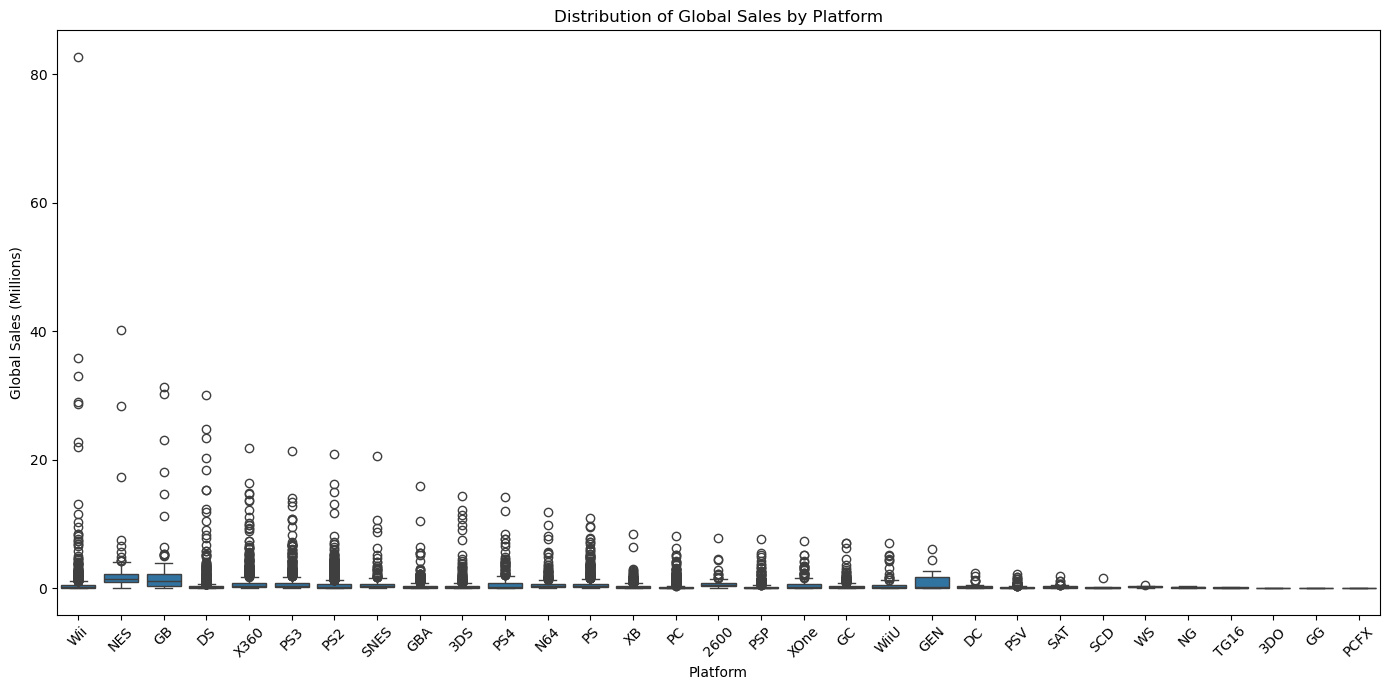

In [19]:
plt.figure(figsize=(14, 7))
sb.boxplot(data=df, x="Platform", y="Global_Sales")
plt.title("Distribution of Global Sales by Platform")
plt.xlabel("Platform")
plt.ylabel("Global Sales (Millions)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [20]:
Platform_sales =df.groupby("Genre")["Global_Sales"].agg(["sum" ,"mean"])
Platform_sales.columns=["Total_Sales","Average_Sales"]
Platform_sales.sort_values("Total_Sales",ascending=False)

,Total_Sales,Average_Sales
Genre,,
Action,1722.88,0.529628
Sports,1309.24,0.568247
Shooter,1026.20,0.800468
Role-Playing,923.84,0.628035
Platform,829.15,0.946518
Misc,797.62,0.466444
Racing,726.77,0.592798
Fighting,444.05,0.531160
Simulation,390.16,0.458472


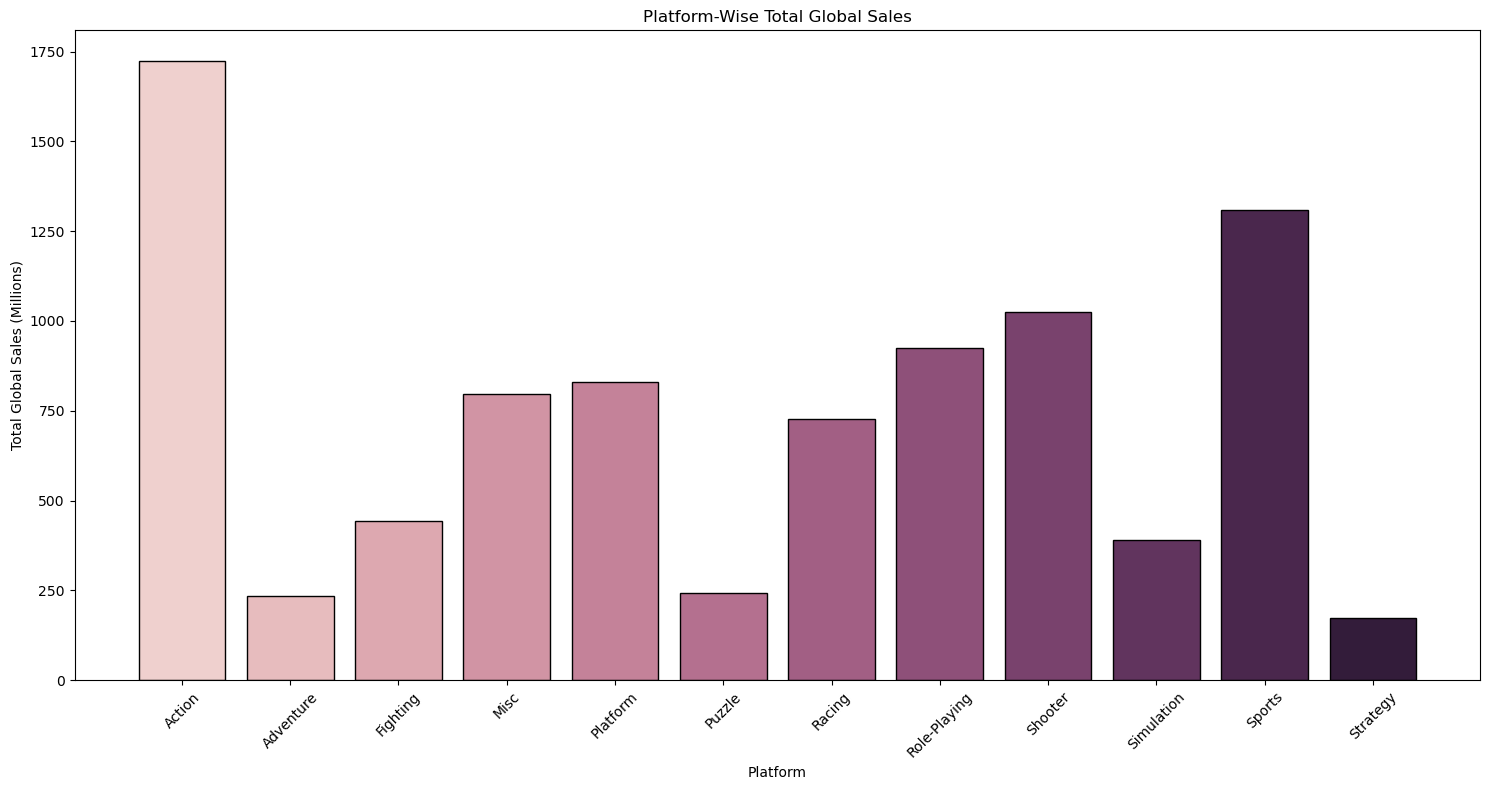

In [21]:
plt.figure(figsize=(15,8))
plt.bar(Platform_sales.index, Platform_sales["Total_Sales"], color=sb.color_palette("ch:start=.2,rot=.3", len(Platform_sales)), edgecolor='black')
plt.title("Platform-Wise Total Global Sales")
plt.xlabel("Platform")
plt.ylabel("Total Global Sales (Millions)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [22]:
regional_sales = df[ ["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales"]].agg(["sum", "mean"])
regional_sales

,NA_Sales,EU_Sales,JP_Sales,Other_Sales
sum,4333.430000,2409.120000,1284.300000,789.010000
mean,0.265415,0.147554,0.078661,0.048325


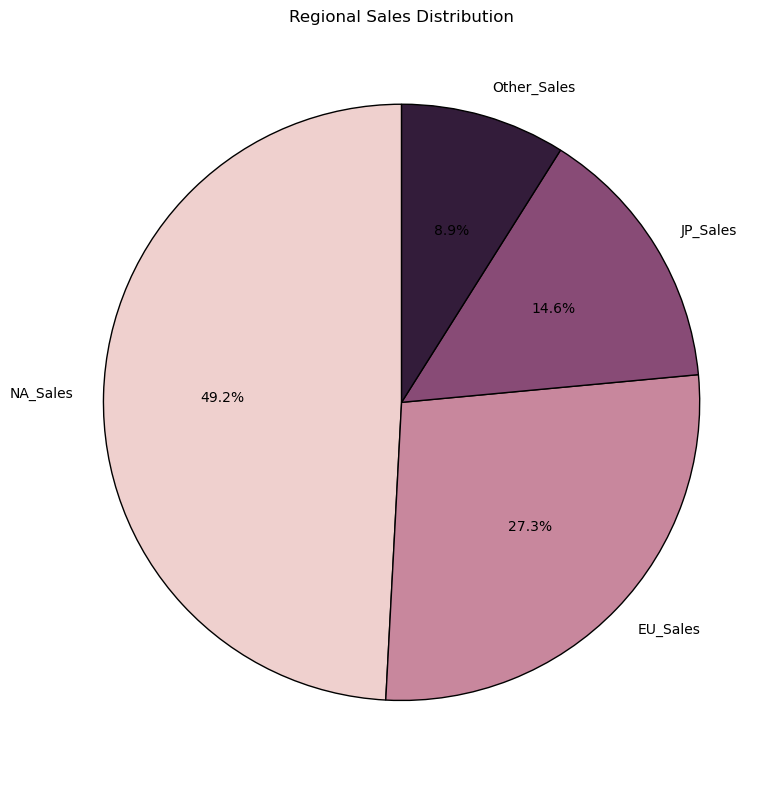

In [44]:
regional_sales = df[["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales"]].sum()
plt.figure(figsize=(8, 8))
plt.pie( regional_sales, labels=regional_sales.index, autopct="%1.1f%%",startangle=90,colors=sb.color_palette("ch:start=.2,rot=.3", 4), wedgeprops={"edgecolor": "black", "linewidth": 1})
plt.title("Regional Sales Distribution", fontsize=12,)
plt.tight_layout()
plt.show()

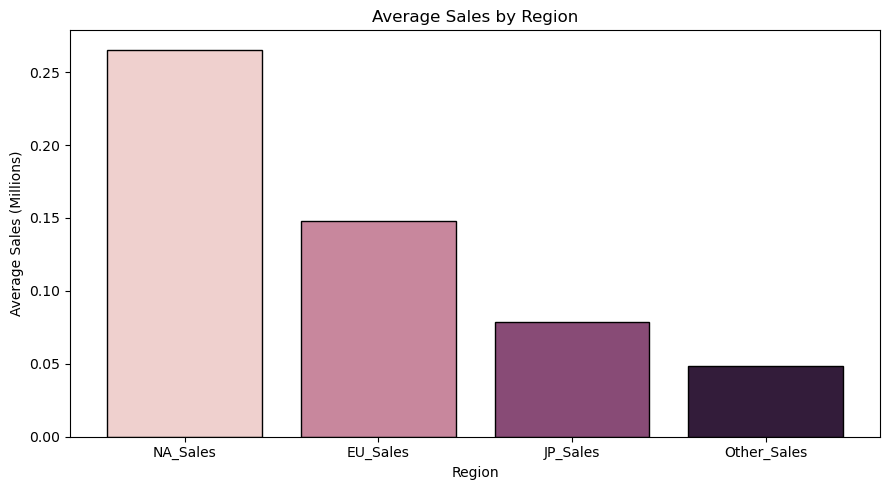

In [24]:
plt.figure(figsize=(9,5))
plt.bar(regional_mean.index, regional_mean.values, color=sb.color_palette("ch:start=.2,rot=.3", len(regional_mean)), edgecolor='black')
plt.title("Average Sales by Region")
plt.xlabel("Region")
plt.ylabel("Average Sales (Millions)")
plt.tight_layout()
plt.show()

# Top Selling Games Analysis:

In [25]:
df.groupby ('Name')['Global_Sales'].sum().nlargest(10)


Name
Wii Sports                        82.74
Grand Theft Auto V                55.92
Super Mario Bros.                 45.31
Tetris                            35.84
Mario Kart Wii                    35.82
Wii Sports Resort                 33.00
Pokemon Red/Pokemon Blue          31.37
Call of Duty: Modern Warfare 3    30.83
New Super Mario Bros.             30.01
Call of Duty: Black Ops II        29.72
Name: Global_Sales, dtype: float64

## What are the top-selling games based on global sales revenue

### Wii Sports ranks first among the best-selling games in the dataset, with global sales of 82.74 million units. Grand Theft Auto V ranks second with 55.92 million units, followed by Super Mario Bros. with 45.31 million units. The results show that Wii Sports has the highest global sales among the games analysed.


In [5]:
df['Global_Sales'].sum()

np.float64(8920.440000000002)

## What is the total global sales revenue across all years

### The total global sales across all years are approximately 8,820.36 million units. This represents the combined worldwide sales of all video games included in the dataset across the recorded years. It provides an overview of the overall sales volume of the video game market represented in the dataset.

In [5]:
df.Year.unique()

array([2006., 1985., 2008., 2009., 1996., 1989., 1984., 2005., 1999.,
       2007., 2010., 2013., 2004., 1990., 1988., 2002., 2001., 2011.,
       1998., 2015., 2012., 2014., 1992., 1997., 1993., 1994., 1982.,
       2003., 1986., 2000.,   nan, 1995., 2016., 1991., 1981., 1987.,
       1980., 1983., 2020., 2017.])

# Platform Performance Analysis:

In [6]:
df.Platform.unique()

array(['Wii', 'NES', 'GB', 'DS', 'X360', 'PS3', 'PS2', 'SNES', 'GBA',
       '3DS', 'PS4', 'N64', 'PS', 'XB', 'PC', '2600', 'PSP', 'XOne', 'GC',
       'WiiU', 'GEN', 'DC', 'PSV', 'SAT', 'SCD', 'WS', 'NG', 'TG16',
       '3DO', 'GG', 'PCFX'], dtype=object)

In [8]:
platform_sales=df.groupby('Platform')['Global_Sales'].sum()
platform_sales.sort_values(ascending=False)
platform_sales

Platform
2600      97.08
3DO        0.10
3DS      247.46
DC        15.97
DS       822.49
GB       255.45
GBA      318.50
GC       199.36
GEN       28.36
GG         0.04
N64      218.88
NES      251.07
NG         1.44
PC       258.82
PCFX       0.03
PS       730.66
PS2     1255.64
PS3      957.84
PS4      278.10
PSP      296.28
PSV       61.93
SAT       33.59
SCD        1.87
SNES     200.05
TG16       0.16
WS         1.42
Wii      926.71
WiiU      81.86
X360     979.96
XB       258.26
XOne     141.06
Name: Global_Sales, dtype: float64

In [13]:
platform_sales=df.groupby('Platform')['Global_Sales'].mean().nlargest(5)
platform_sales


Platform
GB      2.606633
NES     2.561939
GEN     1.050370
SNES    0.837029
PS4     0.827679
Name: Global_Sales, dtype: float64

## Are there any platforms that consistently produce top-selling games over time 

### GB and NES have the highest average global sales, suggesting that they were particularly successful in producing top-selling games.

In [9]:
platform_sales.nlargest(5)

Platform
PS2     1255.64
X360     979.96
PS3      957.84
Wii      926.71
DS       822.49
Name: Global_Sales, dtype: float64

## Which platform has the highest total global sales revenue

### PlayStation 2 (PS2) recorded the highest total global sales, with 1,233.46 million units. Xbox 360 ranked second with 969.61 million units, followed by PlayStation 3 (PS3) with 949.35 million units. These results indicate that PS2 was the leading platform in terms of cumulative global sales in the dataset.


In [33]:
yearly_platform_sales = df.groupby( ["Year", "Platform"])["Global_Sales"].sum()
yearly_platform_sales

Year        Platform
1980-01-01  2600        11.38
1981-01-01  2600        35.77
1982-01-01  2600        28.86
1983-01-01  2600         5.83
            NES         10.96
                        ...  
2016-01-01  X360         0.83
            XOne        12.37
2017-01-01  PS4          0.03
            PSV          0.02
2020-01-01  DS           0.29
Name: Global_Sales, Length: 241, dtype: float64

plt.figure(figsize=(14, 6))
sb.boxplot(data=df, x="Platform", y="Global_Sales")
plt.title("Distribution of Global Sales Across Platforms")
plt.xlabel("Gaming Platform")
plt.ylabel("Global Sales (Millions)")
plt.xticks(rotation=45)
plt.show()

## How does the distribution of global sales revenue vary across different platforms 

### The platform sales distribution shows that sales vary considerably across individual games. Some platforms have games with exceptionally high sales, while many other games have comparatively lower sales. Therefore, a platform's total sales depend on both the number of games available and the sales performance of individual titles.


# Genre Analysis:

In [8]:
 df.groupby("Genre")["Global_Sales"].sum().sort_values(ascending=False)

Genre
Action          1751.18
Sports          1330.93
Shooter         1037.37
Role-Playing     927.37
Platform         831.37
Misc             809.96
Racing           732.04
Fighting         448.91
Simulation       392.20
Puzzle           244.95
Adventure        239.04
Strategy         175.12
Name: Global_Sales, dtype: float64

## What are the most popular genres in terms of global sales revenue

### Action, Sports, and Shooter are the most popular game genres in terms of global sales. Action games lead by a significant margin, while Strategy, Adventure, and Puzzle have comparatively lower global sales.

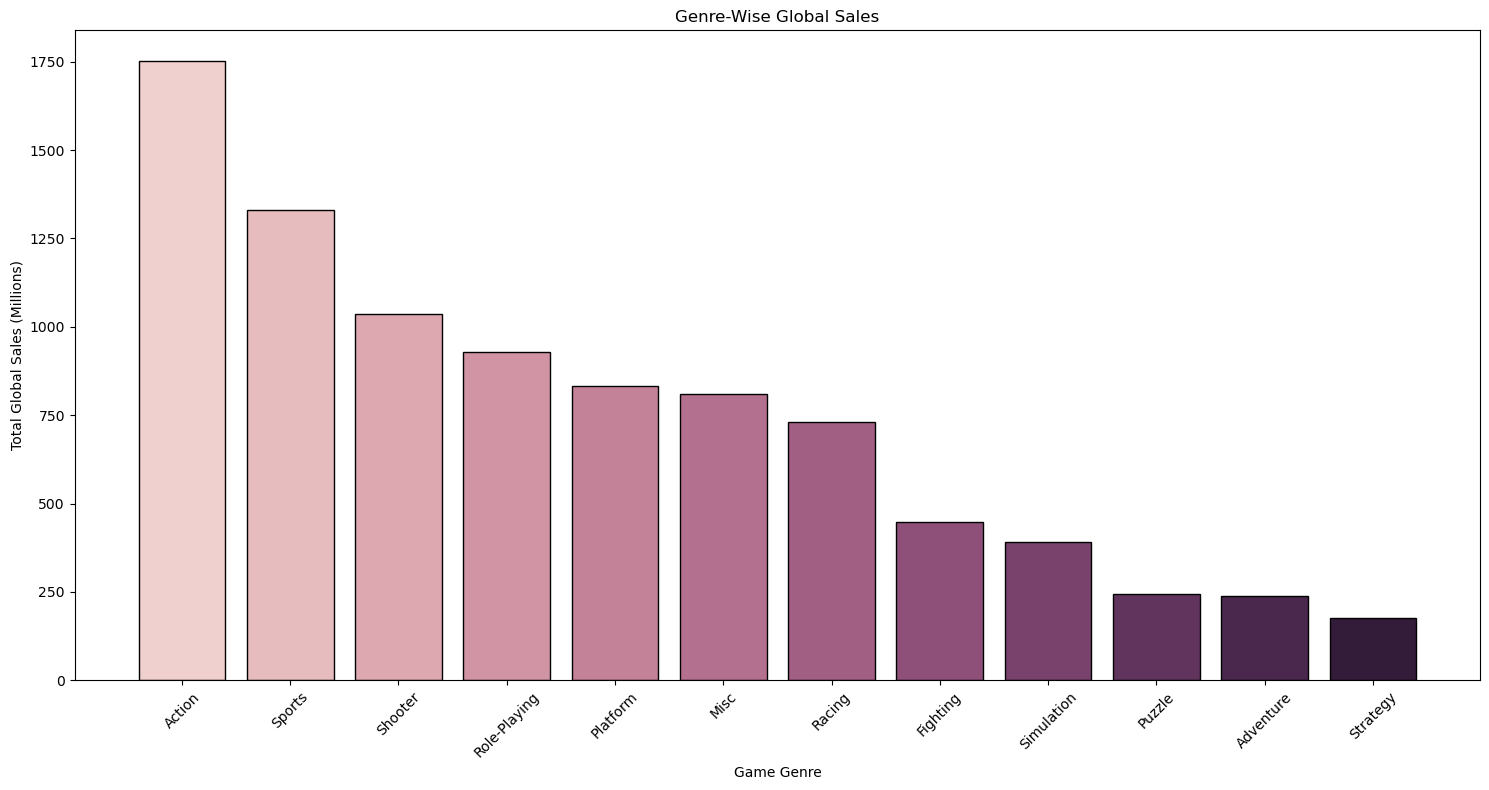

In [9]:
genre_sales = df.groupby("Genre")["Global_Sales"].sum().sort_values(ascending=False)

plt.figure(figsize=(15,8))
plt.bar(genre_sales.index, genre_sales.values, color=sb.color_palette("ch:start=.2,rot=.3", len(genre_sales)), edgecolor='black')
plt.title("Genre-Wise Global Sales")
plt.xlabel("Game Genre")
plt.ylabel("Total Global Sales (Millions)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Action games recorded the highest total global sales at 1,722.88 million units. Sports games ranked second with 1,309.24 million units, followed by Shooter games with 1,026.20 million units. Strategy games recorded the lowest total sales at 173.43 million units. This indicates that Action, Sports, and Shooter games contributed substantially to overall global sales.


In [35]:
Year_Genre_Sales=df.groupby(["Year", "Genre"])["Global_Sales"].sum()
Year_Genre_Sales

Year        Genre       
1980-01-01  Action           0.34
            Fighting         0.77
            Misc             2.71
            Shooter          7.07
            Sports           0.49
                            ...  
2016-01-01  Sports          14.60
            Strategy         0.50
2017-01-01  Action           0.01
            Role-Playing     0.04
2020-01-01  Simulation       0.29
Name: Global_Sales, Length: 389, dtype: float64

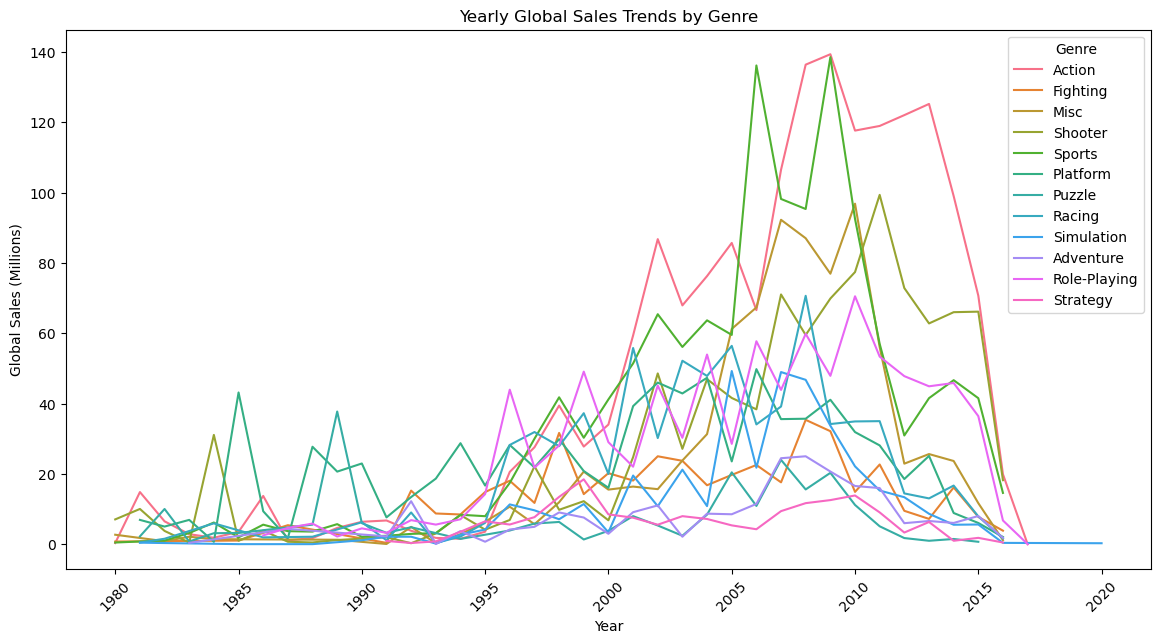

In [36]:
yearly_genre = df.groupby(["Year", "Genre"])["Global_Sales"].sum().reset_index()
plt.figure(figsize=(14, 7))
sb.lineplot(data=yearly_genre, x="Year", y="Global_Sales", hue="Genre")
plt.title("Yearly Global Sales Trends by Genre")
plt.xlabel("Year")
plt.ylabel("Global Sales (Millions)")
plt.xticks(rotation=45)
plt.show()

## Can we identify any emerging trends or shifts in genre preferences over time

### The year-wise genre analysis helps compare how sales of different game genres changed over time. The trends can reveal periods when particular genres performed strongly or experienced lower sales. This analysis helps explore changes in gaming preferences across the years included in the dataset.


# Publisher Performance Analysis

In [76]:
publisher_sales = df.groupby("Publisher")["Global_Sales"].sum().sort_values(ascending=False)
publisher_sales.head(10)

Publisher
Nintendo                        1784.43
Electronic Arts                 1093.39
Activision                       721.41
Sony Computer Entertainment      607.28
Ubisoft                          473.54
Take-Two Interactive             399.30
THQ                              340.44
Konami Digital Entertainment     278.56
Sega                             270.70
Namco Bandai Games               253.65
Name: Global_Sales, dtype: float64

## Which publisher has the highest total global sales revenue according to genre 

### Nintendo recorded the highest total global sales among publishers, with 1,784.43 million units. Electronic Arts ranked second with 1,093.39 million units, followed by Activision with 721.41 million units. These findings show that Nintendo was the leading publisher by total global sales in the analyzed dataset.


In [6]:
regional_sales = df.groupby("Publisher")[["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales"]].sum()
regional_sales



,NA_Sales,EU_Sales,JP_Sales,Other_Sales
Publisher,,,,
10TACLE Studios,0.07,0.04,0.00,0.00
1C Company,0.01,0.07,0.00,0.02
20th Century Fox Video Games,1.82,0.10,0.00,0.01
2D Boy,0.00,0.03,0.00,0.01
3DO,6.48,3.04,0.00,0.63
...,...,...,...,...
id Software,0.02,0.00,0.00,0.00
imageepoch Inc.,0.00,0.00,0.04,0.00
inXile Entertainment,0.02,0.06,0.00,0.01


In [46]:
regional_sales = df.groupby("Publisher")[["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales"]].sum()
NA=regional_sales.nlargest(5,"NA_Sales")
NA

,NA_Sales,EU_Sales,JP_Sales,Other_Sales
Publisher,,,,
Nintendo,815.75,418.30,454.99,95.19
Electronic Arts,584.22,367.38,13.98,127.63
Activision,426.01,213.72,6.54,74.79
Sony Computer Entertainment,265.22,187.55,74.10,80.40
Ubisoft,252.81,163.03,7.33,50.16


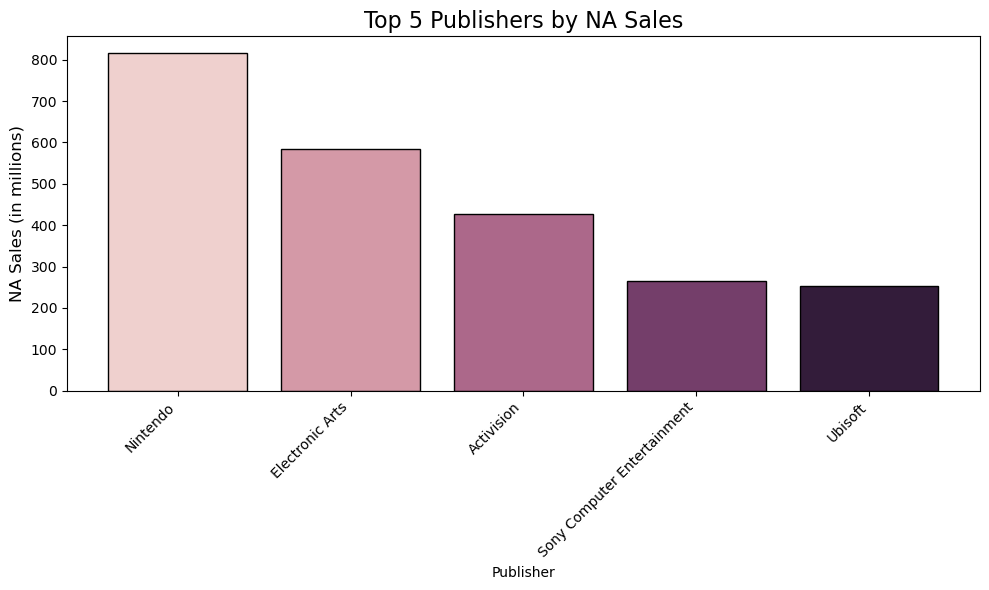

In [56]:
top_5 = regional_sales.nlargest(5, "NA_Sales")
plt.figure(figsize=(10, 6))
plt.bar( top_5.index, top_5["NA_Sales"], color=sb.color_palette("ch:start=.2,rot=.3", 5), edgecolor="black", linewidth=1)
plt.title("Top 5 Publishers by NA Sales", fontsize=16,)
plt.xlabel("Publisher", fontsize=10)
plt.ylabel("NA Sales (in millions)", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [47]:
EU=regional_sales.nlargest(5,"EU_Sales")
EU

,NA_Sales,EU_Sales,JP_Sales,Other_Sales
Publisher,,,,
Nintendo,815.75,418.30,454.99,95.19
Electronic Arts,584.22,367.38,13.98,127.63
Activision,426.01,213.72,6.54,74.79
Sony Computer Entertainment,265.22,187.55,74.10,80.40
Ubisoft,252.81,163.03,7.33,50.16


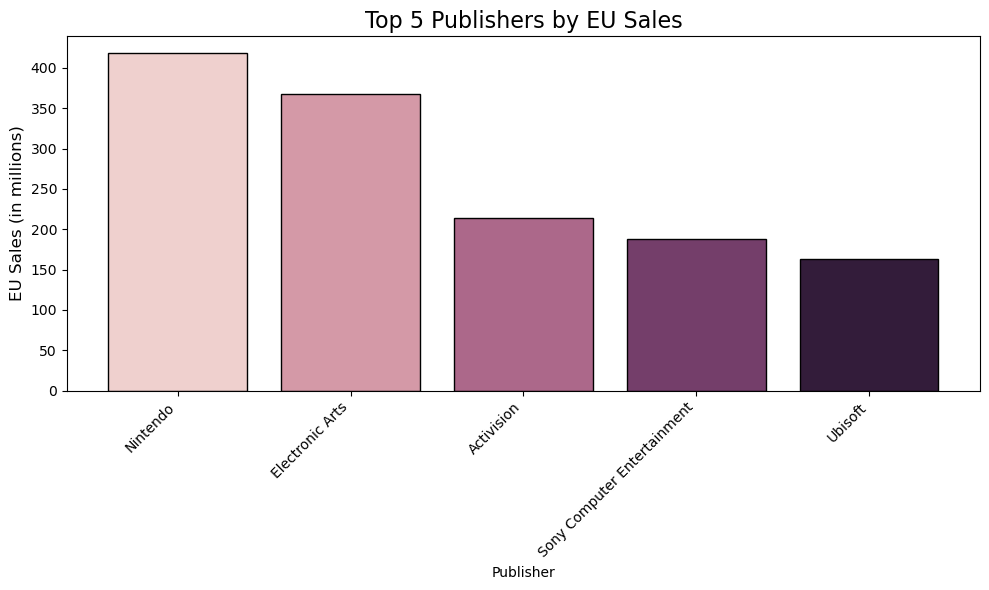

In [57]:
top_5 = regional_sales.nlargest(5, "EU_Sales")
plt.figure(figsize=(10, 6))
plt.bar( top_5.index, top_5["EU_Sales"], color=sb.color_palette("ch:start=.2,rot=.3", 5), edgecolor="black", linewidth=1)
plt.title("Top 5 Publishers by EU Sales", fontsize=16,)
plt.xlabel("Publisher", fontsize=10)
plt.ylabel("EU Sales (in millions)", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [48]:
JP=regional_sales.nlargest(5,"JP_Sales")
JP

,NA_Sales,EU_Sales,JP_Sales,Other_Sales
Publisher,,,,
Nintendo,815.75,418.30,454.99,95.19
Namco Bandai Games,69.38,42.61,126.84,14.64
Konami Digital Entertainment,88.91,68.62,90.93,29.91
Sony Computer Entertainment,265.22,187.55,74.10,80.40
Capcom,78.45,39.16,67.38,14.82


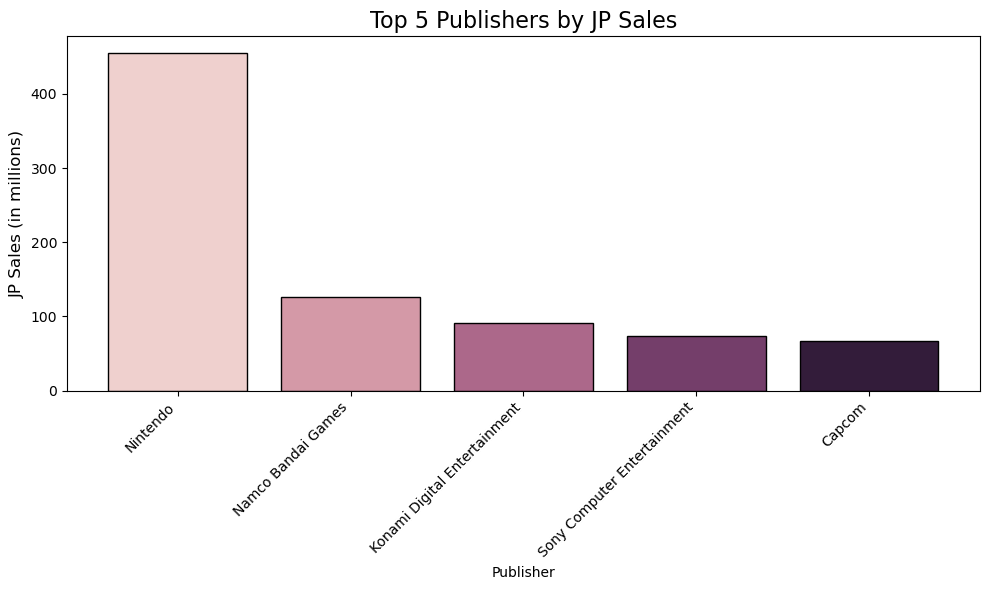

In [58]:
top_5 = regional_sales.nlargest(5, "JP_Sales")
plt.figure(figsize=(10, 6))
plt.bar( top_5.index, top_5["JP_Sales"], color=sb.color_palette("ch:start=.2,rot=.3", 5), edgecolor="black", linewidth=1)
plt.title("Top 5 Publishers by JP Sales", fontsize=16,)
plt.xlabel("Publisher", fontsize=10)
plt.ylabel("JP Sales (in millions)", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [49]:
OTHER_SALES=regional_sales.nlargest(5,"Other_Sales")
OTHER_SALES

,NA_Sales,EU_Sales,JP_Sales,Other_Sales
Publisher,,,,
Electronic Arts,584.22,367.38,13.98,127.63
Nintendo,815.75,418.30,454.99,95.19
Sony Computer Entertainment,265.22,187.55,74.10,80.40
Activision,426.01,213.72,6.54,74.79
Take-Two Interactive,220.47,117.95,5.83,55.20


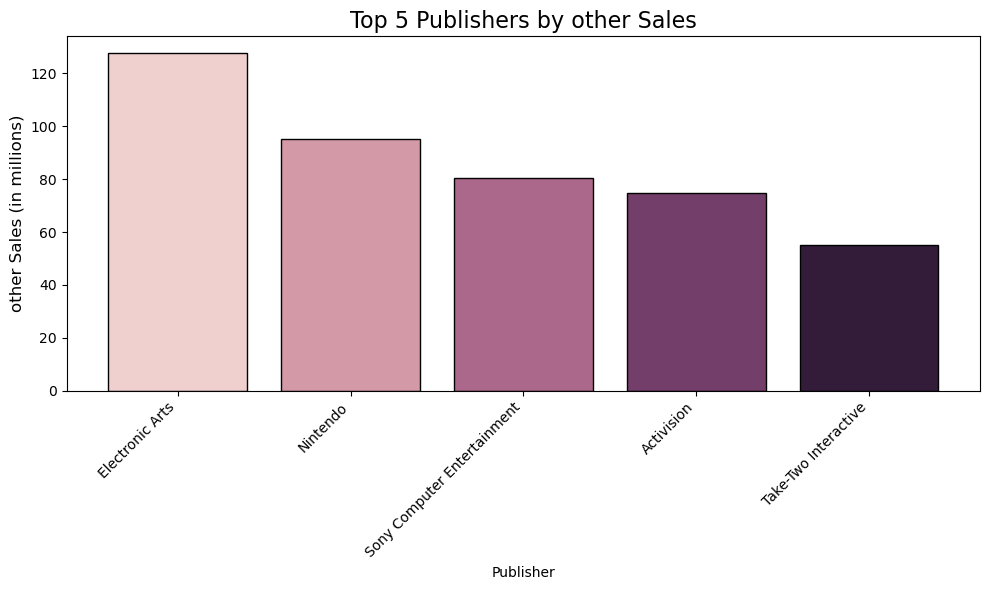

In [59]:
top_5 = regional_sales.nlargest(5, "Other_Sales")
plt.figure(figsize=(10, 6))
plt.bar( top_5.index, top_5["Other_Sales"], color=sb.color_palette("ch:start=.2,rot=.3", 5), edgecolor="black", linewidth=1)
plt.title("Top 5 Publishers by other Sales", fontsize=16,)
plt.xlabel("Publisher", fontsize=10)
plt.ylabel("other Sales (in millions)", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

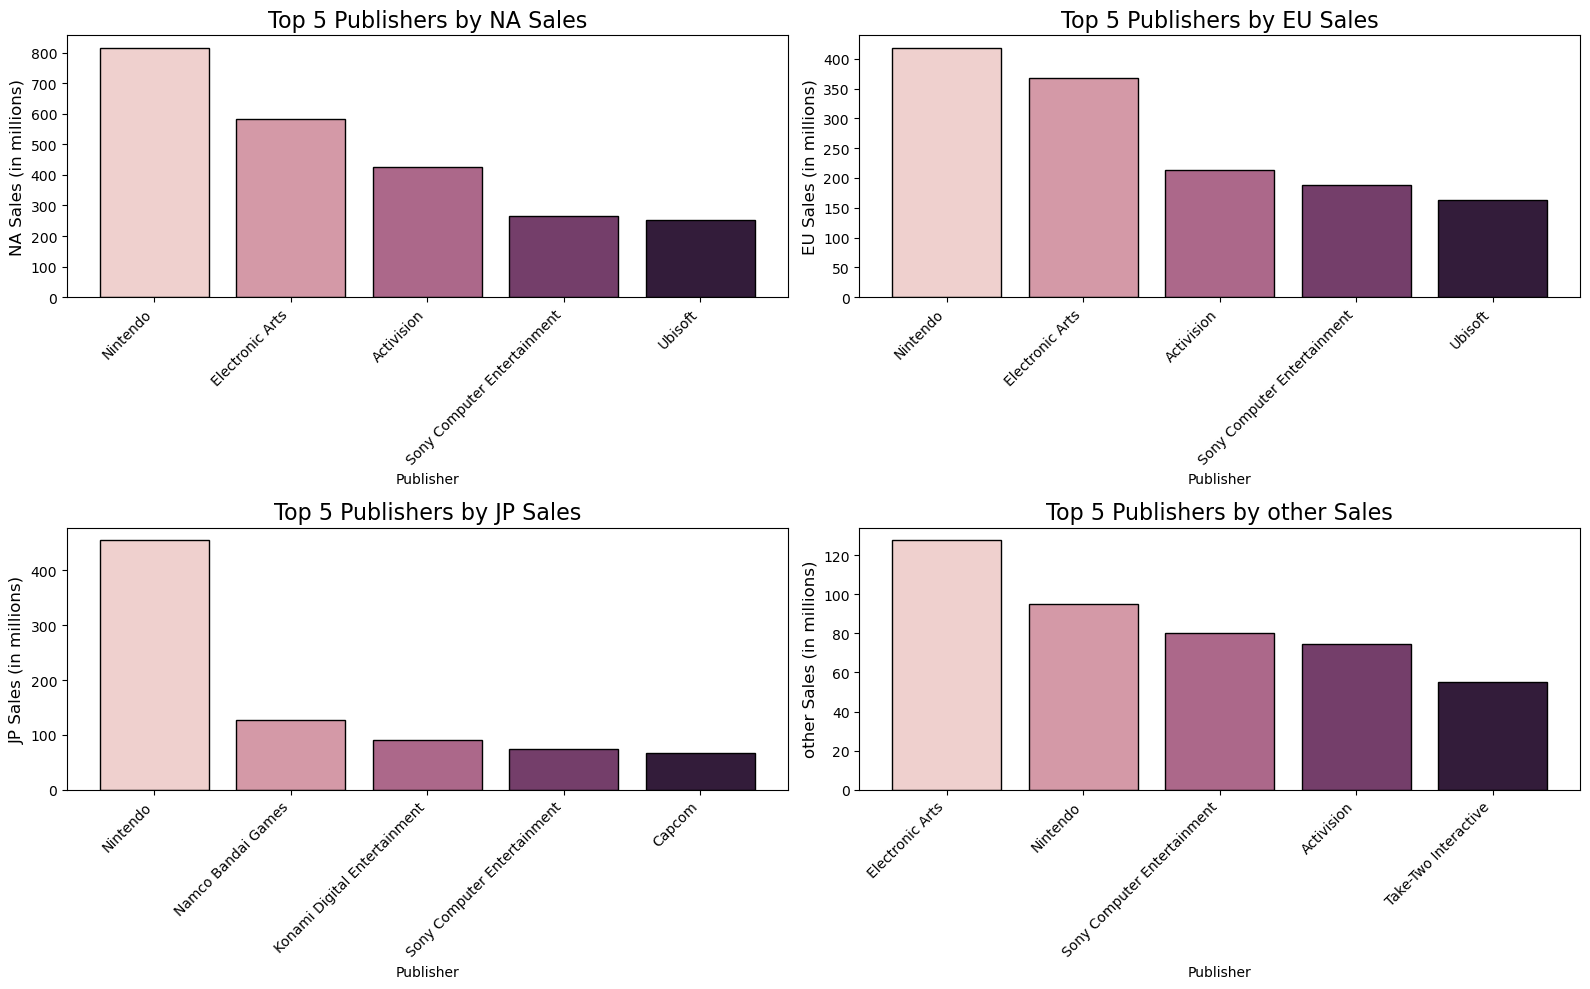

In [61]:
plt.figure(figsize=(16, 10))

# Subplot 1
plt.subplot(2, 2, 1)
top_5 = regional_sales.nlargest(5, "NA_Sales")
plt.bar( top_5.index, top_5["NA_Sales"], color=sb.color_palette("ch:start=.2,rot=.3", 5), edgecolor="black", linewidth=1)
plt.title("Top 5 Publishers by NA Sales", fontsize=16,)
plt.xlabel("Publisher", fontsize=10)
plt.ylabel("NA Sales (in millions)", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
# Subplot 2
plt.subplot(2, 2, 2)
top_5 = regional_sales.nlargest(5, "EU_Sales")
plt.bar( top_5.index, top_5["EU_Sales"], color=sb.color_palette("ch:start=.2,rot=.3", 5), edgecolor="black", linewidth=1)
plt.title("Top 5 Publishers by EU Sales", fontsize=16,)
plt.xlabel("Publisher", fontsize=10)
plt.ylabel("EU Sales (in millions)", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
# Subplot 3
plt.subplot(2, 2, 3)
top_5 = regional_sales.nlargest(5, "JP_Sales")
plt.bar( top_5.index, top_5["JP_Sales"], color=sb.color_palette("ch:start=.2,rot=.3", 5), edgecolor="black", linewidth=1)
plt.title("Top 5 Publishers by JP Sales", fontsize=16,)
plt.xlabel("Publisher", fontsize=10)
plt.ylabel("JP Sales (in millions)", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
# Subplot 4
plt.subplot(2, 2, 4)
top_5 = regional_sales.nlargest(5, "Other_Sales")
plt.bar( top_5.index, top_5["Other_Sales"], color=sb.color_palette("ch:start=.2,rot=.3", 5), edgecolor="black", linewidth=1)
plt.title("Top 5 Publishers by other Sales", fontsize=16,)
plt.xlabel("Publisher", fontsize=10)
plt.ylabel("other Sales (in millions)", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.tight_layout()
plt.show()

## How does the performance of publishers vary in different regions

## The regional sales comparison shows how publishers contribute to sales across North America, Europe, Japan, and Other regions. Comparing these regions helps identify differences in publishers' sales performance across markets. It also provides a broader understanding of their global performance beyond total sales alone.

# Regional Sales Analysis:

In [4]:
rs = df[["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales"]].sum()
rs


NA_Sales       4392.95
EU_Sales       2434.13
JP_Sales       1291.02
Other_Sales     797.75
dtype: float64

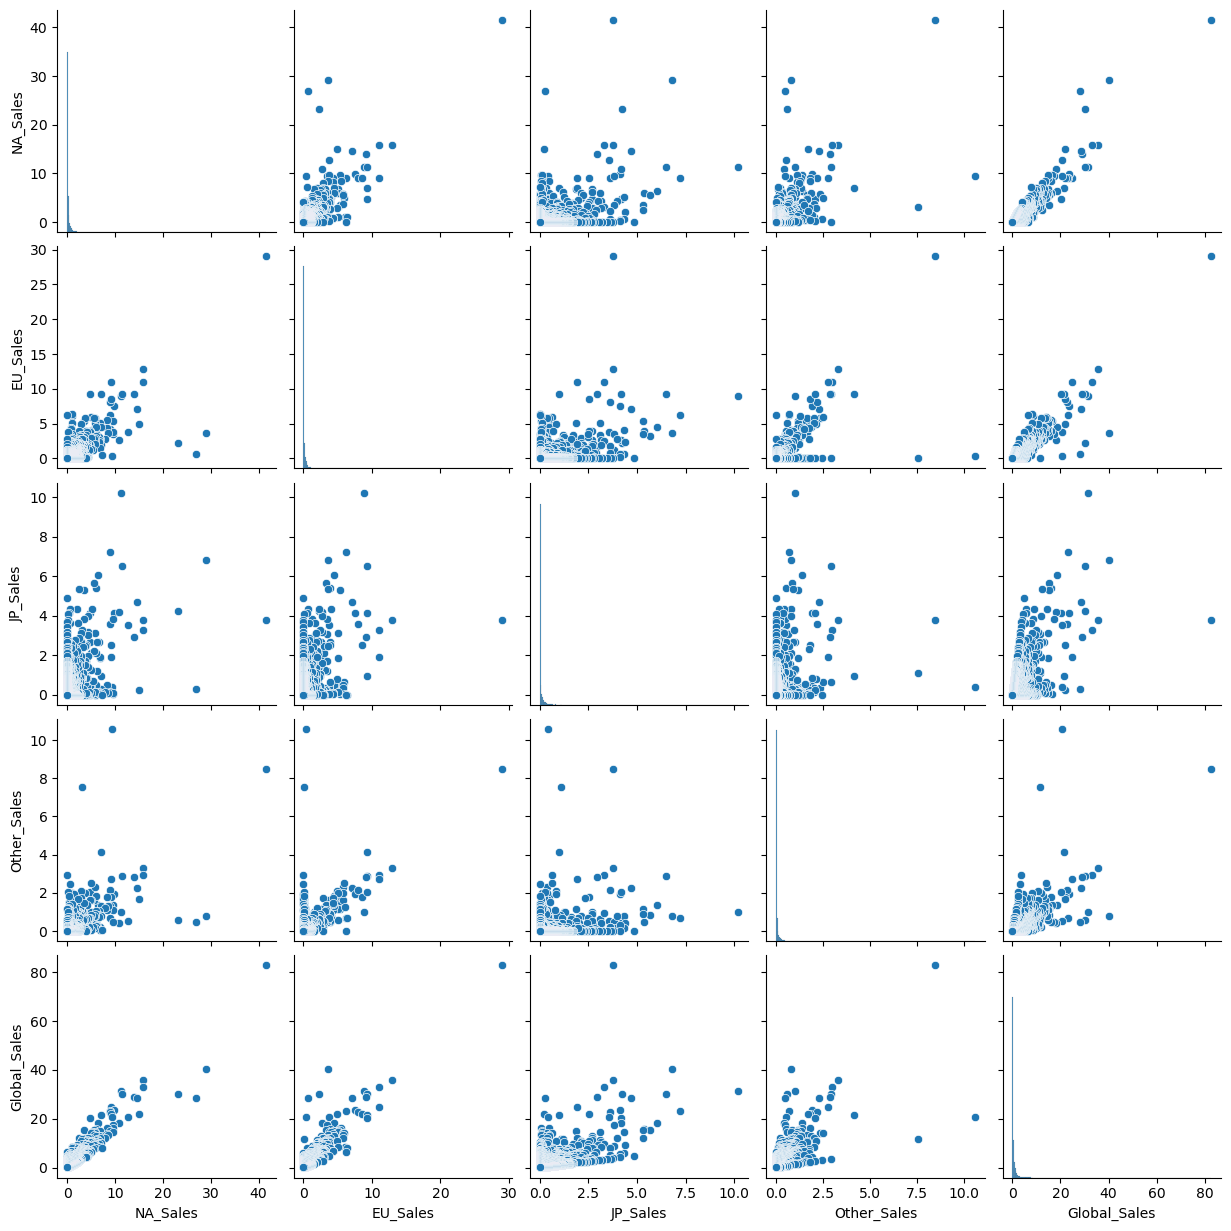

In [5]:
rs = df[['NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales','Global_Sales']]
sb.pairplot(rs)
plt.show()


## How do sales revenues vary across different regions (e.g., North America, Europe, Japan, Other)


### North America recorded the highest total sales at 4,333.43 million units, followed by Europe at 2,434.12 million units. Japan contributed 1,284.30 million units, while Other regions recorded 789.01 million units. These results show that North America contributed the largest share of total regional sales in the dataset.


In [11]:
genre_sales = df.groupby('Genre')[['NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales','Global_Sales']].sum()


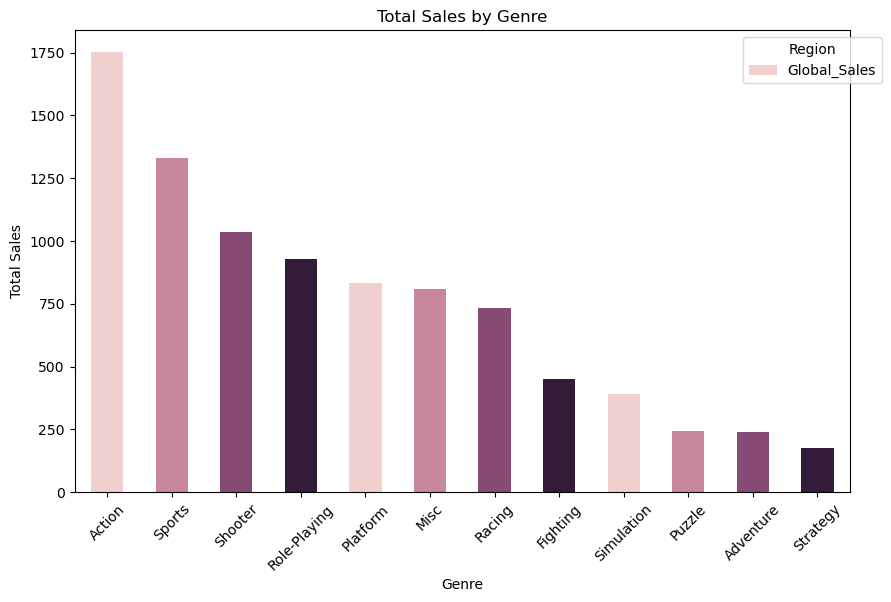

In [10]:
genre_sales.plot(kind='bar', figsize=(10, 6),
                 color=sb.color_palette("ch:start=.2,rot=.3", 4))
plt.title('Total Sales by Genre')
plt.xlabel('Genre')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.legend(title='Region', bbox_to_anchor=(1.05,1))
plt.show()

## Can we identify any regional preferences or trends in gaming preferences 

### North America and Europe mainly prefer Action and Sports games, whereas Japan shows a stronger preference for Role-Playing games. This indicates that gaming preferences vary across different regions.